# Final top-5 routing analysis: 96 vs. 200 languages

This notebook is the concise comparison layer over the per-checkpoint routing artifacts. It keeps expert, head, and up-projection axes distinct; cross-method comparisons use normalized permutation-invariant metrics, while cross-panel identity comparisons use per-module Hungarian alignment.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import Image, display

cwd = Path.cwd().resolve()
repo = next((candidate for candidate in (cwd, *cwd.parents) if (candidate / 'pipeline_tools').is_dir()), None)
if repo is None:
    raise FileNotFoundError(f'Could not locate repository root from {cwd}')
root96 = repo / 'outputs/routing_analysis/moe_study_final_top5_96_langs_initial_1000seq'
root200 = repo / 'outputs/routing_analysis/moe_study_final_top5_200_langs_initial_1000seq'
comparison = repo / 'outputs/routing_analysis/moe_study_final_top5_96_vs_200_comparison'
for required in (root96 / 'summary.json', root200 / 'summary.json', comparison / 'comparison_summary.json'):
    if not required.exists():
        raise FileNotFoundError(f'Required completed artifact is missing: {required}')

## Completion and routing semantics

In [2]:
completion = []
for panel, root in [('96', root96), ('200', root200)]:
    summary = json.loads((root / 'summary.json').read_text())
    for run in summary['runs']:
        meta = json.loads((Path(run['metadata'])).read_text())
        completion.append({
            'panel': panel,
            'approach': run['run_id'],
            'status': run['status'],
            'routing_basis': run['routing_basis'],
            'axis': run['axis_name'],
            'routing_ids': run['routing_ids'],
            'modules': run['captured_modules'],
            'choices': meta['adapter_config'].get('expert_num') or meta['adapter_config'].get('mola_num_experts') or meta['adapter_config'].get('lora_num') or meta['adapter_config'].get('num_up_projections'),
            'static_validation': (meta.get('static_validation') or {}).get('status', 'n/a'),
        })
pd.DataFrame(completion).sort_values(['approach', 'panel']).reset_index(drop=True)

,panel,approach,status,routing_basis,axis,routing_ids,modules,choices,static_validation
0,200,hydralora_r2,complete,token_conditioned,head,215,224,8,n/a
1,96,hydralora_r2,complete,token_conditioned,head,102,224,8,n/a
2,200,moelora_tr32_e16_k8,complete,static_language_conditioned,expert,215,1,16,passed
3,96,moelora_tr32_e16_k8,complete,static_language_conditioned,expert,102,1,16,passed
4,200,moelora_tr64_e32_k8,complete,static_language_conditioned,expert,215,1,32,passed
5,96,moelora_tr64_e32_k8,complete,static_language_conditioned,expert,102,1,32,passed
6,200,mola_tr16_e8_k6,complete,token_conditioned,true_expert,215,224,8,n/a
7,96,mola_tr16_e8_k6,complete,token_conditioned,true_expert,102,224,8,n/a
8,200,mtllora_lr5e5_r8_nup16,complete,static_language_conditioned,up_projection,215,224,16,passed
9,96,mtllora_lr5e5_r8_nup16,complete,static_language_conditioned,up_projection,102,224,16,passed


## Permutation-invariant comparison

In [3]:
metrics = pd.read_csv(comparison / 'routing_metrics.csv')
overall = metrics.query("group_type == 'overall'").copy()
overall[['panel', 'run_id', 'peft_type', 'axis_name', 'routing_basis', 'normalized_entropy_mean', 'effective_choices_mean', 'max_probability_mean', 'load_cv', 'unused_choice_fraction']].sort_values(['run_id', 'panel']).reset_index(drop=True)

,panel,run_id,peft_type,axis_name,routing_basis,normalized_entropy_mean,effective_choices_mean,max_probability_mean,load_cv,unused_choice_fraction
0,96,hydralora_r2,HYDRALORA,head,token_conditioned,0.922840,6.897685,0.267343,0.017062,0.0
1,200,hydralora_r2,HYDRALORA,head,token_conditioned,0.918299,6.836680,0.270203,0.036640,0.0
2,96,moelora_tr32_e16_k8,MOELORA,expert,static_language_conditioned,0.742235,7.834410,0.159454,0.138526,0.0
3,200,moelora_tr32_e16_k8,MOELORA,expert,static_language_conditioned,0.741306,7.814230,0.163379,0.300044,0.0
4,96,moelora_tr64_e32_k8,MOELORA,expert,static_language_conditioned,0.596840,7.914292,0.147141,0.427252,0.0
5,200,moelora_tr64_e32_k8,MOELORA,expert,static_language_conditioned,0.597095,7.921015,0.146830,0.544959,0.0
6,96,mola_tr16_e8_k6,MOLA,true_expert,token_conditioned,0.564026,3.481208,0.524155,0.064527,0.0
7,200,mola_tr16_e8_k6,MOLA,true_expert,token_conditioned,0.483337,3.009840,0.588055,0.096751,0.0
8,96,mtllora_lr5e5_r8_nup16,MTLLORA,up_projection,static_language_conditioned,0.776050,8.707604,0.254994,0.009922,0.0
9,200,mtllora_lr5e5_r8_nup16,MTLLORA,up_projection,static_language_conditioned,0.776800,8.716657,0.255036,0.007262,0.0


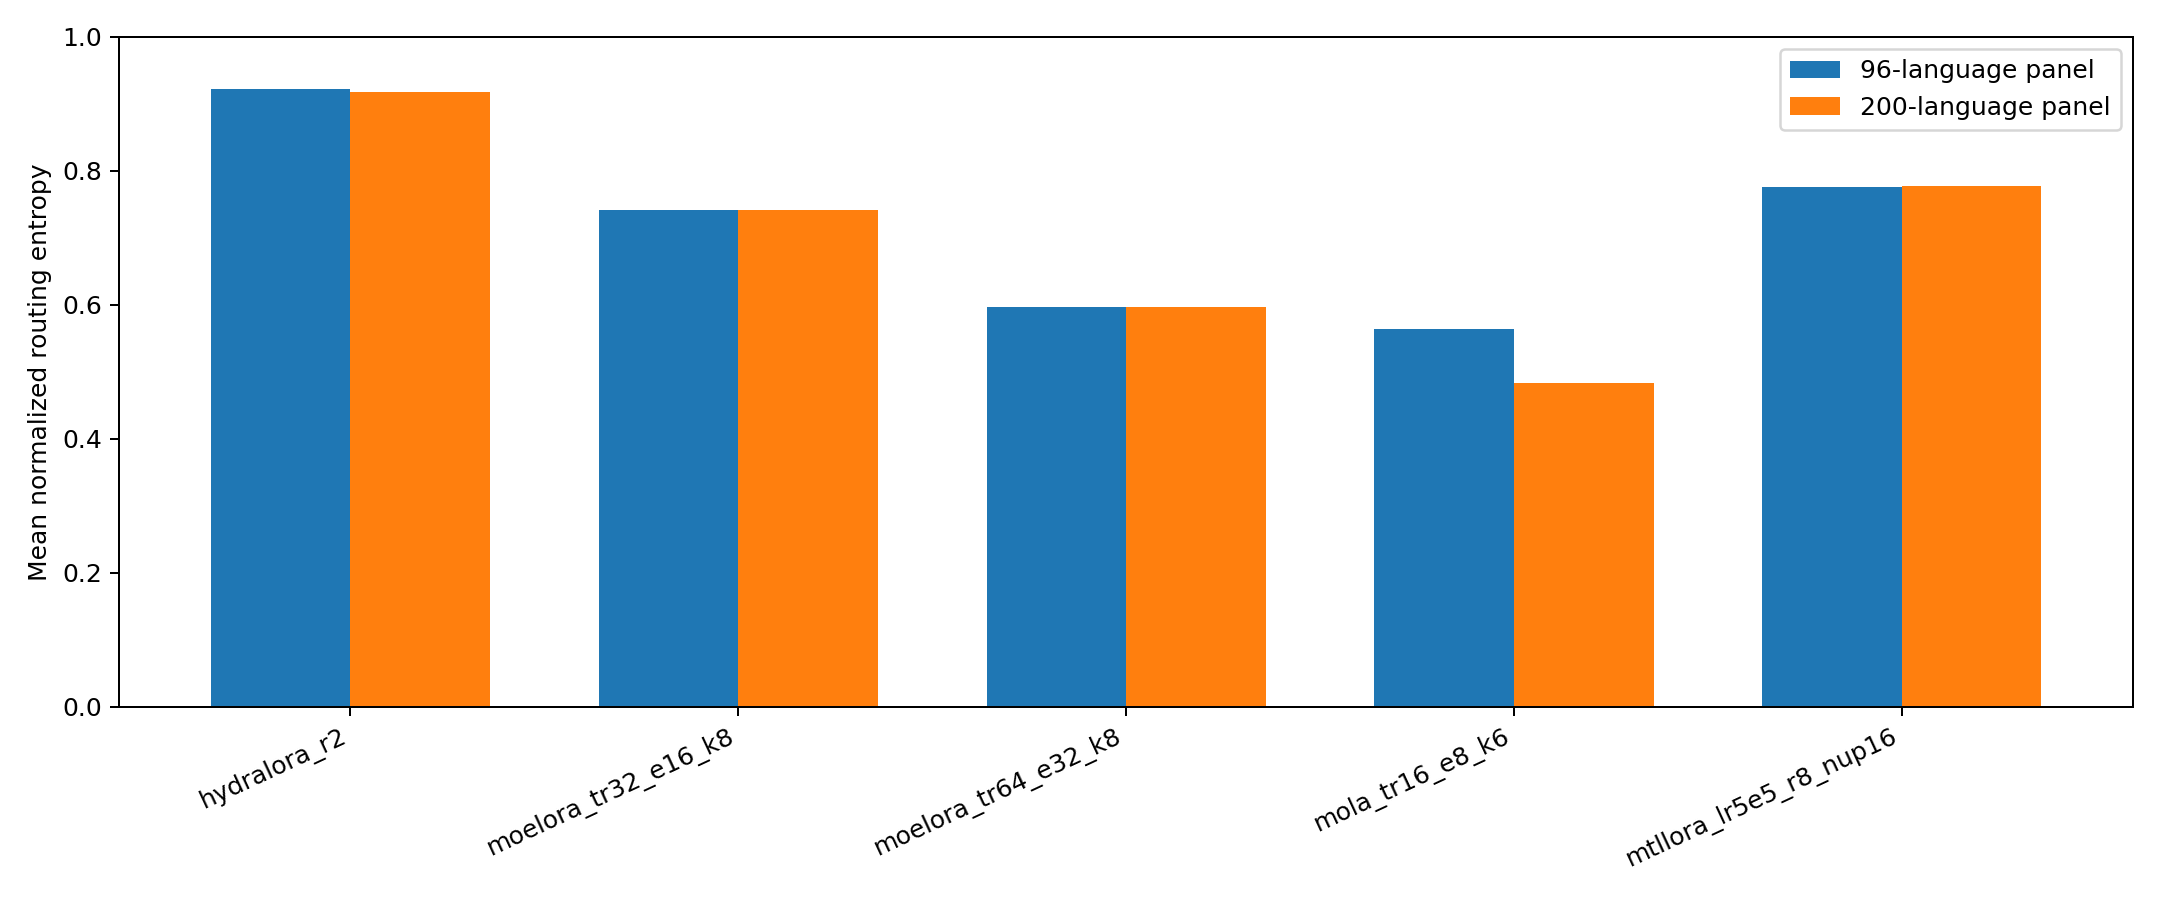

In [4]:
display(Image(filename=str(comparison / 'figures/normalized_entropy_96_vs_200.png')))

## Shared-language stability after choice alignment

The rows below use the 102 shared routing IDs. Choice labels are aligned independently per adapted module, so the comparison does not assume that independently trained choice indices have the same identity.

In [5]:
stability = pd.read_csv(comparison / 'shared_language_stability.csv')
stability.groupby('run_id', as_index=False).agg(
    shared_routing_ids=('language', 'nunique'),
    aligned_cosine_mean=('aligned_cosine_mean', 'mean'),
    aligned_cosine_std=('aligned_cosine_mean', 'std'),
    js_distance_mean=('jensen_shannon_distance_mean', 'mean'),
).sort_values('aligned_cosine_mean', ascending=False).reset_index(drop=True)

,run_id,shared_routing_ids,aligned_cosine_mean,aligned_cosine_std,js_distance_mean
0,hydralora_r2,102,0.858698,0.021911,0.228321
1,mola_tr16_e8_k6,102,0.721858,0.012583,0.434960
2,moelora_tr32_e16_k8,102,0.584770,0.132904,0.635574
3,mtllora_lr5e5_r8_nup16,102,0.513872,0.013267,0.569791
4,moelora_tr64_e32_k8,102,0.442822,0.167687,0.738007


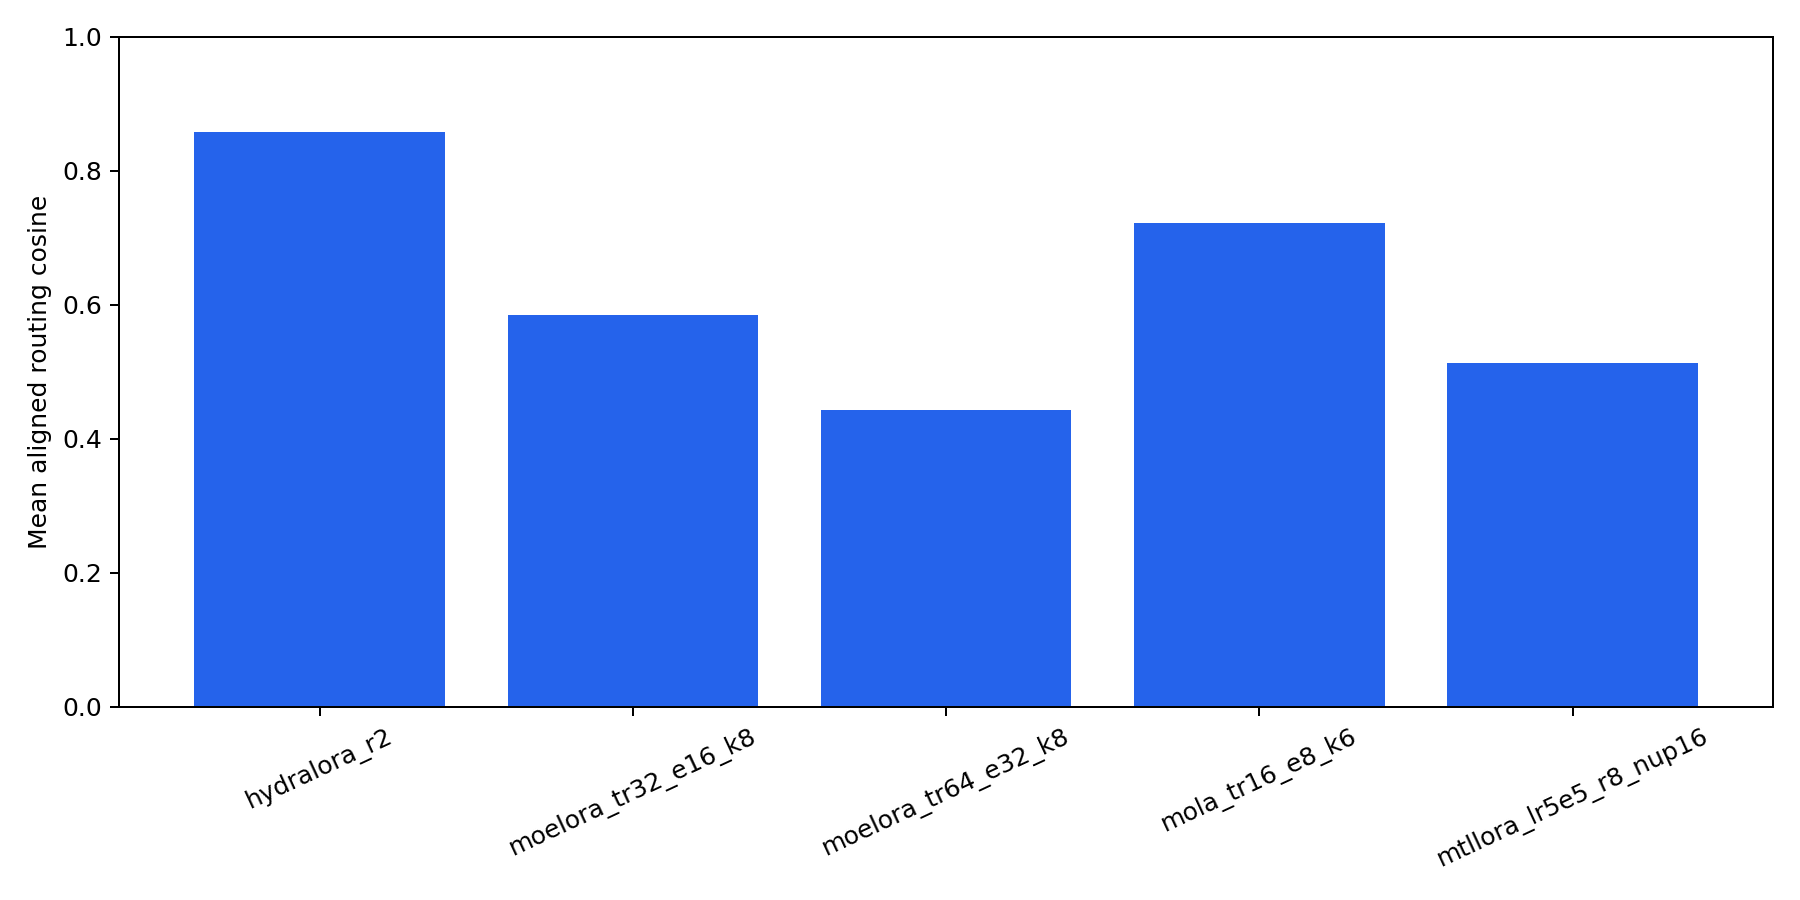

In [6]:
display(Image(filename=str(comparison / 'figures/shared_language_routing_stability.png')))

## Interpretation guardrails

- MoLA and HydraLoRA statistics are estimated from 1,000 documents per routing ID with padding tokens excluded.
- MoE-LoRA and MTL-LoRA routing is language-conditioned and input-independent; their matrices are extracted directly from checkpoint parameters and validated with short forward passes.
- A lower entropy indicates stronger specialization, not automatically better downstream quality.
- Expert, head, and up-projection identities are not compared directly across approaches.